Name: Huang Chihwei

USC ID: 9265220160

Homework: HW3

In [1]:
import os
import re
import glob

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

pd.set_option('display.max_columns', 50)
pd.set_option('display.width', 200)
DATA_DIR = '../data/AReM'
SERIES = ['avg_rss12', 'var_rss12', 'avg_rss13', 'var_rss13', 'avg_rss23', 'var_rss23']
RNG_SEED = 552

# 1. Time Series Classification Part 1: Feature Creation/Extraction

## 1a. Download the AReM data

I downloaded the data from the UCI website and put it in `../data/AReM`. There are 7 folders, one for each activity:
`bending1`, `bending2`, `cycling`, `lying`, `sitting`, `standing` and `walking`.

**Data cleaning.** Two files have small problems:
- `bending2/dataset4.csv` uses spaces between values instead of commas.
- `sitting/dataset8.csv` has 479 rows instead of 480. One reading is missing.

The code below skips the lines that start with `#`. It splits each line on commas or spaces, so both file formats work.
I keep the file with 479 rows as it is and compute the features from the 479 values.

In [2]:
def load_instance(path):
    """Read one AReM file, tolerating comma- or whitespace-separated rows."""
    rows = []
    with open(path) as f:
        for line in f:
            line = line.strip()
            if not line or line.startswith('#'):
                continue
            rows.append([float(x) for x in re.split(r'[,\s]+', line) if x])
    arr = np.array(rows)
    return pd.DataFrame(arr[:, 1:7], columns=SERIES, index=arr[:, 0].astype(int))


def dataset_number(path):
    return int(re.search(r'dataset(\d+)', os.path.basename(path)).group(1))


instances = []
for activity in sorted(d for d in os.listdir(DATA_DIR) if os.path.isdir(f'{DATA_DIR}/{d}')):
    for path in sorted(glob.glob(f'{DATA_DIR}/{activity}/*.csv'), key=dataset_number):
        instances.append({'activity': activity,
                          'dataset': dataset_number(path),
                          'data': load_instance(path)})

print('Number of instances:', len(instances))
summary = pd.DataFrame([{'activity': x['activity'], 'dataset': x['dataset'],
                         'n_rows': len(x['data']), 'n_series': x['data'].shape[1]} for x in instances])
print(summary.groupby('activity').size().to_string())
print('\nInstances whose length is not 480:')
print(summary[summary.n_rows != 480].to_string(index=False))

Number of instances: 88
activity
bending1     7
bending2     6
cycling     15
lying       15
sitting     15
standing    15
walking     15

Instances whose length is not 480:
activity  dataset  n_rows  n_series
 sitting        8     479         6


## 1b. Train / test split

Test data: datasets 1 and 2 in `bending1` and `bending2`, and datasets 1, 2 and 3 in all other folders.
All other files are training data. This gives 19 test instances and 69 training instances.

In [3]:
def is_test(activity, dataset):
    return dataset <= (2 if activity.startswith('bending') else 3)

for x in instances:
    x['split'] = 'test' if is_test(x['activity'], x['dataset']) else 'train'

pd.crosstab(pd.Series([x['activity'] for x in instances], name='activity'),
            pd.Series([x['split'] for x in instances], name='split'), margins=True)

split,test,train,All
activity,,,
bending1,2,5,7
bending2,2,4,6
cycling,3,12,15
lying,3,12,15
sitting,3,12,15
standing,3,12,15
walking,3,12,15
All,19,69,88


## 1c. Feature Extraction

### 1c.i Time-domain features commonly used in time series classification

Time-domain features are numbers computed directly from the raw values of a time series. They turn a long series into
a few numbers that a classifier can use. Common ones are:

| Group | Feature | What it tells us |
| --- | --- | --- |
| Center | Mean | The average value |
| Center | Median | The middle value |
| Center | Mode | The most common value |
| Extremes | Minimum | The smallest value |
| Extremes | Maximum | The largest value |
| Extremes | Range | Maximum minus minimum |
| Spread | Variance and standard deviation | How far values are from the mean |
| Spread | Interquartile range | 3rd quartile minus 1st quartile |
| Spread | Mean absolute deviation | Average distance from the mean |
| Spread | Coefficient of variation | Standard deviation divided by the mean |
| Percentiles | 1st and 3rd quartiles | The values below which 25% and 75% of the data fall |
| Percentiles | Other percentiles | For example the 10th and 90th percentiles |
| Shape | Skewness | Whether the values lean to one side |
| Shape | Kurtosis | Whether the values have heavy tails |
| Energy | Root mean square | The typical size of the signal |
| Energy | Signal energy | Sum of the squared values |
| Change over time | Autocorrelation | How similar the series is to a shifted copy of itself |
| Change over time | Mean crossing rate | How often the series crosses its mean |
| Change over time | Number of peaks | How many local high points there are |
| Change over time | Slope | Whether the series goes up or down overall |
| Change over time | Mean of absolute differences | How much the value changes from one step to the next |
| Complexity | Entropy | How random or regular the series is |

### 1c.ii Extract min, max, mean, median, std, 1st quartile, 3rd quartile for each of the 6 time series

I use the features as they are, without normalization. The standard deviation divides by n minus 1.
The quartiles use the pandas default method.

In [4]:
STATS = ['min', 'max', 'mean', 'median', 'std', '1st_quart', '3rd_quart']

def extract_features(df):
    feats = {}
    for i, col in enumerate(df.columns, start=1):
        s = df[col]
        feats[f'min{i}'] = s.min()
        feats[f'max{i}'] = s.max()
        feats[f'mean{i}'] = s.mean()
        feats[f'median{i}'] = s.median()
        feats[f'std{i}'] = s.std()
        feats[f'1st_quart{i}'] = s.quantile(0.25)
        feats[f'3rd_quart{i}'] = s.quantile(0.75)
    return feats

features = pd.DataFrame([extract_features(x['data']) for x in instances])
features.index = pd.RangeIndex(1, len(features) + 1, name='Instance')
FEATURE_COLS = list(features.columns)

meta = pd.DataFrame([{'activity': x['activity'], 'dataset': x['dataset'], 'split': x['split']}
                     for x in instances], index=features.index)

print('Feature matrix shape:', features.shape)
features

Feature matrix shape: (88, 42)


,min1,max1,mean1,median1,std1,1st_quart1,3rd_quart1,min2,max2,mean2,median2,std2,1st_quart2,3rd_quart2,min3,max3,mean3,median3,std3,1st_quart3,3rd_quart3,min4,max4,mean4,median4,std4,1st_quart4,3rd_quart4,min5,max5,mean5,median5,std5,1st_quart5,3rd_quart5,min6,max6,mean6,median6,std6,1st_quart6,3rd_quart6
Instance,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,
1,37.25,45.00,40.624792,40.50,1.476967,39.25,42.0000,0.0,1.30,0.358604,0.430,0.322605,0.00,0.5000,4.00,29.50,19.040937,19.250,4.462952,16.00,23.2500,0.0,7.23,0.832542,0.50,0.965659,0.0000,1.1200,27.25,38.25,34.311292,35.00,2.188449,33.0000,36.00,0.00,1.92,0.570583,0.43,0.582915,0.0000,1.3000
2,38.00,45.67,42.812812,42.50,1.435550,42.00,43.6700,0.0,1.22,0.372437,0.470,0.289158,0.00,0.5000,2.00,29.50,20.096979,21.000,3.893737,19.00,22.2500,0.0,5.76,0.876438,0.50,1.047259,0.0000,1.1450,27.67,38.50,33.024583,33.00,1.995255,32.0000,34.50,0.00,3.11,0.571083,0.43,0.601010,0.0000,1.3000
3,35.00,47.40,43.954500,44.33,1.558835,43.00,45.0000,0.0,1.70,0.426250,0.470,0.338690,0.00,0.5000,6.50,29.75,22.122354,23.000,3.030943,19.75,24.0000,0.0,4.44,0.497312,0.43,0.550657,0.0000,0.8300,29.00,38.50,35.588458,36.00,1.999604,35.3625,36.50,0.00,1.79,0.493292,0.43,0.513506,0.0000,0.9400
4,33.00,47.75,42.179812,43.50,3.670666,39.15,45.0000,0.0,3.00,0.696042,0.500,0.630860,0.00,1.1200,8.50,30.00,22.183625,23.000,3.810469,20.50,24.3725,0.0,5.15,0.989917,0.83,0.953730,0.4300,1.3000,20.00,38.67,33.493917,35.00,3.849448,30.4575,36.33,0.00,2.18,0.613521,0.50,0.524317,0.0000,1.0000
5,33.00,45.75,41.678063,41.75,2.243490,41.33,42.7500,0.0,2.83,0.535979,0.500,0.405469,0.43,0.7100,3.00,28.25,19.006563,19.125,4.087107,16.50,22.0625,0.0,6.42,0.841875,0.50,0.928801,0.4300,1.1200,23.67,37.50,29.857083,30.00,2.411026,28.4575,31.25,0.00,1.79,0.383292,0.43,0.389164,0.0000,0.5000
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
84,19.50,45.33,33.586875,34.25,4.650935,30.25,37.0000,0.0,14.67,4.576562,4.260,2.461077,2.87,6.1050,7.33,23.25,15.317854,15.330,2.970440,13.25,17.2700,0.0,9.00,3.227229,3.10,1.647474,2.0500,4.2600,6.33,25.00,15.892146,16.00,3.283983,13.7300,18.25,0.00,8.32,3.259729,3.11,1.640243,2.0500,4.3225
85,19.75,45.50,34.322750,35.25,4.752477,31.00,38.0000,0.0,13.47,4.456333,3.900,2.599284,2.49,5.9700,6.25,22.25,15.209771,15.250,2.711022,13.50,17.0000,0.0,9.00,3.277229,3.11,1.500046,2.1700,4.3900,6.25,23.25,15.550458,15.75,3.119856,13.5000,17.75,0.00,9.67,3.432563,3.20,1.732727,2.1575,4.5650
86,19.50,46.00,34.546229,35.25,4.842294,31.25,37.8125,0.0,12.47,4.371958,4.135,2.360448,2.49,5.8000,7.00,22.67,15.185729,15.250,2.757604,13.25,17.0000,0.0,8.34,3.028687,2.86,1.665184,1.7900,4.1100,7.00,22.75,15.759542,15.75,2.823124,14.0000,17.75,0.00,10.00,3.338125,3.08,1.656742,2.1600,4.3350


In [5]:
# Full dataset with labels (reused for the classification part in HW4)
full = pd.concat([meta, features], axis=1)
train_df = full[full.split == 'train']
test_df = full[full.split == 'test']
print('train:', train_df.shape, ' test:', test_df.shape)

train: (69, 45)  test: (19, 45)


### 1c.iii Standard deviation of each feature and 90% bootstrap confidence interval

For each of the 42 features, I compute its standard deviation over the 88 instances.

To get a 90% confidence interval with the bootstrap:
1. Draw 88 instances at random with replacement.
2. Compute the standard deviation of each feature on this sample.
3. Repeat steps 1 and 2 for B = 2000 times.
4. The 5th and 95th percentiles of the 2000 values are the lower and upper limits of the interval.

In [6]:
B = 2000
rng = np.random.default_rng(RNG_SEED)
X = features.to_numpy()
n = X.shape[0]

boot_idx = rng.integers(0, n, size=(B, n))
boot_std = np.array([X[idx].std(axis=0, ddof=1) for idx in boot_idx])   # B x 42

std_ci = pd.DataFrame({
    'std': X.std(axis=0, ddof=1),
    'CI_lower_5%': np.percentile(boot_std, 5, axis=0),
    'CI_upper_95%': np.percentile(boot_std, 95, axis=0),
}, index=FEATURE_COLS)
std_ci.index.name = 'feature'
pd.set_option('display.max_rows', 100)
std_ci.round(4)

,std,CI_lower_5%,CI_upper_95%
feature,,,
min1,9.5700,8.2529,10.7615
max1,4.3944,3.3631,5.2696
mean1,5.3357,4.6948,5.9134
median1,5.4401,4.7785,6.0125
std1,1.7722,1.5647,1.9468
1st_quart1,6.1536,5.5490,6.6770
3rd_quart1,5.1389,4.3561,5.8383
min2,0.0000,0.0000,0.0000
max2,5.0627,4.6387,5.3949


To check my result, I also use `scipy.stats.bootstrap`. It gives almost the same intervals. The first 14 features are
shown below.

In [7]:
check = stats.bootstrap((X,), lambda a, axis: np.std(a, axis=axis, ddof=1), confidence_level=0.90,
                        n_resamples=B, method='percentile', random_state=RNG_SEED)
pd.DataFrame({'scipy_lower': check.confidence_interval.low, 'scipy_upper': check.confidence_interval.high},
             index=FEATURE_COLS).round(4).head(14)

,scipy_lower,scipy_upper
min1,8.2717,10.7240
max1,3.3692,5.2484
mean1,4.7033,5.8782
median1,4.8080,5.9929
std1,1.5665,1.9508
1st_quart1,5.6010,6.6477
3rd_quart1,4.3232,5.8300
min2,0.0000,0.0000
max2,4.6441,5.3955
mean2,1.4076,1.7085


Note: `min2` and `min4` are 0 in every instance, so their standard deviation and interval are 0. These two features
are useless. `min6` is 0 in almost every instance, so its standard deviation is close to 0.

### 1c.iv Selecting the three most important time-domain features

To choose the features, I check how well each one separates the 7 activities. I use the ANOVA F-statistic.
A large F means the feature is very different between activities but similar within the same activity.
I compute F for each of the 6 time series using **only the training set**, and then take the average over the 6 series.

In [8]:
def anova_f(col):
    groups = [g[col].to_numpy() for _, g in train_df.groupby('activity')]
    if np.ptp(np.concatenate(groups)) == 0:
        return np.nan          # constant feature (e.g. min of variance series)
    return stats.f_oneway(*groups).statistic

f_table = pd.DataFrame({s: [anova_f(f'{s}{i}') for i in range(1, 7)] for s in STATS},
                       index=[f'series {i} {c}' for i, c in enumerate(SERIES, 1)]).T
f_table['mean F over series'] = f_table.mean(axis=1, skipna=True)
f_table.sort_values('mean F over series', ascending=False).round(1)

,series 1 avg_rss12,series 2 var_rss12,series 3 avg_rss13,series 4 var_rss13,series 5 avg_rss23,series 6 var_rss23,mean F over series
mean,15.9,900.2,26.4,651.8,33.4,581.5,368.2
3rd_quart,8.5,807.0,28.1,561.9,32.2,664.8,350.4
median,17.5,477.0,19.4,800.8,28.6,563.1,317.7
1st_quart,21.4,265.5,21.2,244.8,25.5,346.3,154.1
std,9.1,360.9,15.2,128.6,7.8,133.4,109.2
max,1.5,47.7,31.7,29.3,37.0,33.0,30.0
min,11.0,NaN,22.7,NaN,24.1,0.8,14.6


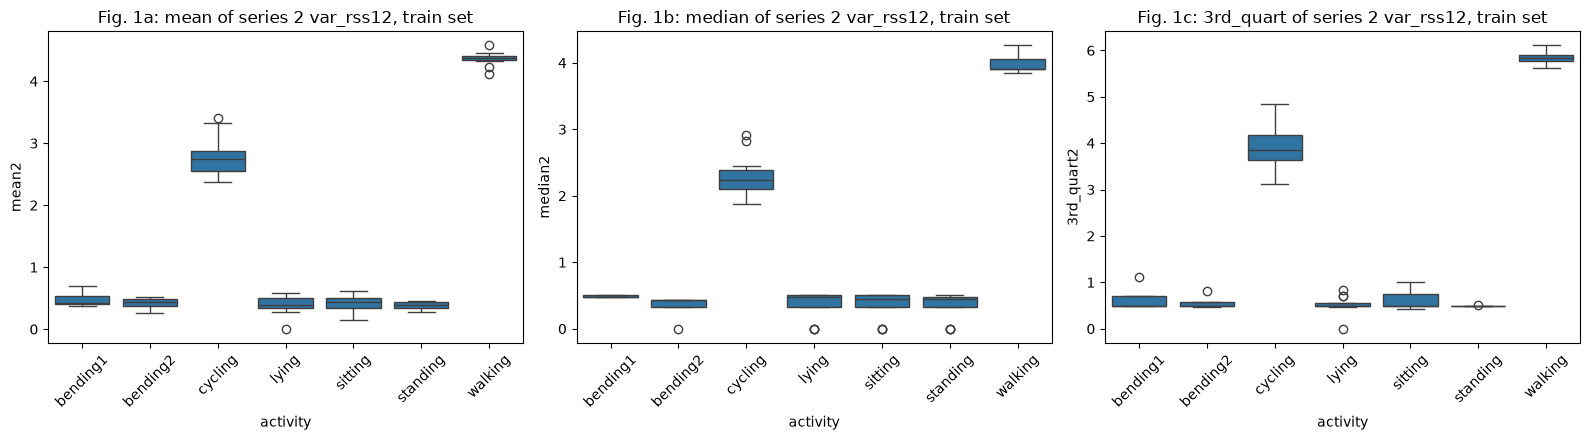

In [9]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
for ax, s, tag in zip(axes, ['mean', 'median', '3rd_quart'], 'abc'):
    sns.boxplot(data=train_df, x='activity', y=f'{s}2', ax=ax)
    ax.set_title(f'Fig. 1{tag}: {s} of series 2 var_rss12, train set')
    ax.tick_params(axis='x', rotation=45)
plt.tight_layout()
plt.show()

**Selected features: mean, median and 3rd quartile.**

- These three features have the highest average F. They separate the activities best.
- They describe the usual level of the signal. One strange value does not change them much.
- Min and max have the lowest F. Min is almost always 0 for the variance series. Max can change a lot because of one
  single spike.
- Standard deviation is also useful because it shows how much the signal moves. Still, its F is lower than the three
  selected features.

The assignment suggests min, mean and max. That is also a fair choice, but in this data mean, median and 3rd quartile
work better.

In [10]:
SELECTED = ['mean', 'median', '3rd_quart']
selected_cols = [f'{s}{i}' for i in range(1, 7) for s in SELECTED]
full[['activity', 'split'] + selected_cols].head()

,activity,split,mean1,median1,3rd_quart1,mean2,median2,3rd_quart2,mean3,median3,3rd_quart3,mean4,median4,3rd_quart4,mean5,median5,3rd_quart5,mean6,median6,3rd_quart6
Instance,,,,,,,,,,,,,,,,,,,,
1,bending1,test,40.624792,40.50,42.00,0.358604,0.43,0.50,19.040937,19.250,23.2500,0.832542,0.50,1.120,34.311292,35.0,36.00,0.570583,0.43,1.30
2,bending1,test,42.812812,42.50,43.67,0.372437,0.47,0.50,20.096979,21.000,22.2500,0.876438,0.50,1.145,33.024583,33.0,34.50,0.571083,0.43,1.30
3,bending1,train,43.954500,44.33,45.00,0.426250,0.47,0.50,22.122354,23.000,24.0000,0.497312,0.43,0.830,35.588458,36.0,36.50,0.493292,0.43,0.94
4,bending1,train,42.179812,43.50,45.00,0.696042,0.50,1.12,22.183625,23.000,24.3725,0.989917,0.83,1.300,33.493917,35.0,36.33,0.613521,0.50,1.00
5,bending1,train,41.678063,41.75,42.75,0.535979,0.50,0.71,19.006563,19.125,22.0625,0.841875,0.50,1.120,29.857083,30.0,31.25,0.383292,0.43,0.50


# 2. ISLR 3.7.4

*I collect a set of data with n = 100 observations containing a single predictor and a quantitative response. I then fit a
linear regression model to the data, as well as a separate cubic regression, i.e.
$Y = \beta_0 + \beta_1 X + \beta_2 X^2 + \beta_3 X^3 + \epsilon$.*

**a. Suppose that the true relationship between X and Y is linear, i.e. $Y = \beta_0 + \beta_1 X + \epsilon$.
Consider the training RSS for the linear regression, and also the training RSS for the cubic regression. Would we expect
one to be lower than the other, would we expect them to be the same, or is there not enough information to tell?**

The cubic regression will have a lower training RSS.

If we set $\beta_2 = \beta_3 = 0$, the cubic model becomes the linear model. So the cubic model can do anything the
linear model can do, and more. Least squares picks the fit with the smallest training RSS, so the cubic model is never
worse on the training data. Its extra terms also fit some of the noise, so its training RSS is usually a bit lower.

**b. Answer part a using test rather than training RSS.**

The linear regression should have a lower test RSS.

The true relationship is linear, so the linear model is already correct. The cubic model has two extra terms that only
fit noise in the training data. This is overfitting, and it makes the cubic model worse on new data. This may not
happen in every sample, but it is what we expect on average.

**c. Suppose that the true relationship between X and Y is not linear, but we don't know how far it is from linear.
Consider the training RSS for the linear regression, and also the training RSS for the cubic regression. Would we expect
one to be lower than the other, would we expect them to be the same, or is there not enough information to tell?**

The cubic regression will have a lower training RSS.

The reason is the same as in part a. The cubic model includes the linear model, so it always fits the training data at
least as well. The true relationship does not matter here.

**d. Answer part c using test rather than training RSS.**

There is not enough information to tell.

- If the true relationship is far from linear, the linear model misses the curve. The cubic model should have the lower
  test RSS.
- If the true relationship is only a little non-linear, the linear model is almost right and is more stable. The linear
  model may have the lower test RSS.

### Simulation illustrating 3.7.4

I run a small simulation to check the answers. Each run has 100 training points and 10,000 test points, and I repeat
it 500 times. The test RSS is scaled to 100 points so it can be compared with the training RSS.

In [11]:
def simulate(f, reps=500, n=100, n_test=10000, sigma=1.0, seed=RNG_SEED):
    rng = np.random.default_rng(seed)
    res = {'train_RSS_linear': [], 'train_RSS_cubic': [], 'test_RSS_linear': [], 'test_RSS_cubic': []}
    for _ in range(reps):
        x = rng.uniform(-2, 2, n)
        y = f(x) + rng.normal(0, sigma, n)
        xt = rng.uniform(-2, 2, n_test)
        yt = f(xt) + rng.normal(0, sigma, n_test)
        for deg, name in [(1, 'linear'), (3, 'cubic')]:
            coef = np.polyfit(x, y, deg)
            res[f'train_RSS_{name}'].append(np.sum((y - np.polyval(coef, x)) ** 2))
            res[f'test_RSS_{name}'].append(np.mean((yt - np.polyval(coef, xt)) ** 2) * n)
    return {k: np.mean(v) for k, v in res.items()}

scenarios = {
    'truly linear: 1 + 2x': lambda x: 1 + 2 * x,
    'slightly non-linear: 1 + 2x + 0.05x^3': lambda x: 1 + 2 * x + 0.05 * x ** 3,
    'strongly non-linear: 1 + 2x + x^3': lambda x: 1 + 2 * x + x ** 3,
}
pd.DataFrame({k: simulate(f) for k, f in scenarios.items()}).T.round(2)

,train_RSS_linear,train_RSS_cubic,test_RSS_linear,test_RSS_cubic
truly linear: 1 + 2x,97.51,95.53,101.84,103.98
slightly non-linear: 1 + 2x + 0.05x^3,97.97,95.53,102.22,103.98
strongly non-linear: 1 + 2x + x^3,241.01,95.53,251.89,103.98


- Parts a and c: the cubic model always has the lower training RSS.
- Part b: when the truth is linear, the linear model has the lower test RSS.
- Part d: the answer depends on the truth. When the curve is strong, the cubic model wins by a lot. When the curve is
  very small, the linear model still wins.